# 02 — Registration and your first regional volumes

**Before you start** (terminal, venv active): `pip install nilearn antspyx` — ANTsPy is a big download, give it a few minutes. First use of nilearn's dataset functions also downloads files from the internet.

Goal: measure the regions of ONE subject (IXI002). The obstacle: an atlas that names brain regions lives in *standard template space*, and IXI002's head is its own size, shape, and position. So the pipeline is: align the subject to the standard template (registration), use that alignment to carry the atlas's region labels back into the subject, then count voxels per region.

Comments in this notebook point and hint — the code is yours. Function names are given as starting points; figuring out their arguments is part of the exercise (your tools: `help(...)`, tab-completion, and asking Astro).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
from pathlib import Path
import ants 
from nilearn import datasets

## The big idea

Every head is a different size, tilted differently, sitting in a different spot in the scanner. The **MNI152 template** is the field's agreed standard head - an average brain in a fixed coordinate space. **Registration** computes the transformation that lines a real subject up with that template.

Direction matters: we want region volumes *in the subject's own space* (their real sizes, not template-stretched sizes). So we register subject -> template to *learn* the alignment, then use the **inverse** transform to carry the atlas labels *back* into the subject.

In [2]:
# STEP 2 - Load the template
# nilearn's datasets module can load the MNI152 template and its
# brain mask (functions with 'mni152' in their names - find them).
# Load both. Print the template's shape and zooms, then plot its
# middle sagittal/coronal/axial slices like you did in notebook 01.
# Notice: no face, no neck, much tidier than a raw subject scan.
# Question to hold: why do you think the template looks averaged
# and a little blurry compared to IXI002?

template = datasets.load_mni152_template(resolution=2)
mask = datasets.load_mni152_brain_mask(resolution=2)
print("Template shape:", template.shape)
print("Template voxel zooms:", template.header.get_zooms())




Template shape: (99, 117, 95)
Template voxel zooms: (np.float32(2.0), np.float32(2.0), np.float32(2.0))


In [4]:
# STEP 3 - Load the atlas
# Fetch the Harvard-Oxford cortical atlas via nilearn's datasets
# (the 'cort-maxprob-thr25-2mm' variant). The result has two parts:
# a maps image and a list of labels.
# Inspect them:
#   - the maps image is a LABEL image: every voxel holds a whole
#     number - the ID of the region that voxel belongs to (0 = none).
#     Prove it to yourself: how many unique values are in the array?
#   - print the first several label names. Index 0 is 'Background';
#     the label at position i names region ID i.
# How many real regions are there (excluding background)?

atlas = datasets.fetch_atlas_harvard_oxford('cort-maxprob-thr25-2mm')
maps = atlas.maps
labels = atlas.labels
print("Unique region IDs in maps:", np.unique(maps.get_fdata()))
print("First several labels:", labels[:10])
print("Number of real regions (excluding background):", len(labels) - 1) 


[fetch_atlas_harvard_oxford] Dataset directory found: /Users/jacobruss/nilearn_data/fsl
Unique region IDs in maps: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35.
 36. 37. 38. 39. 40. 41. 42. 43. 44. 45. 46. 47. 48.]
First several labels: ['Background', 'Frontal Pole', 'Insular Cortex', 'Superior Frontal Gyrus', 'Middle Frontal Gyrus', 'Inferior Frontal Gyrus, pars triangularis', 'Inferior Frontal Gyrus, pars opercularis', 'Precentral Gyrus', 'Temporal Pole', 'Superior Temporal Gyrus, anterior division']
Number of real regions (excluding background): 48


In [10]:
# STEP 4 - Register IXI002 to the template
# ANTsPy has its own image type - load both files with its
# image_read function (the template too; if your template object
# is a nibabel image, ANTsPy can convert it - look for a
# 'from_nibabel' style helper).
# The workhorse is ants.registration. You must decide:
#   fixed  = the image that stays put (the template)
#   moving = the image that gets aligned (IXI002)
#   type_of_transform = 'Affine' - shifts, rotation, scaling,
#     shearing only. No warping. Why start with the simple one?
# Expect this cell to take on the order of a minute.
# The result is a dictionary - print its keys and look at what
# came back: a warped version of the moving image, and transform
# lists in both directions (fwdtransforms / invtransforms).


nib.save(template, "data/mni152_template_2mm.nii.gz")
template_ants = ants.image_read("data/mni152_template_2mm.nii.gz")
subject_ants = ants.image_read("data/IXI-T1/IXI002-Guys-0828-T1.nii.gz")
reg = ants.registration(fixed=template_ants, moving=subject_ants, type_of_transform='Affine')
print("Registration result keys:", reg.keys())



Registration result keys: dict_keys(['warpedmovout', 'warpedfixout', 'fwdtransforms', 'invtransforms'])


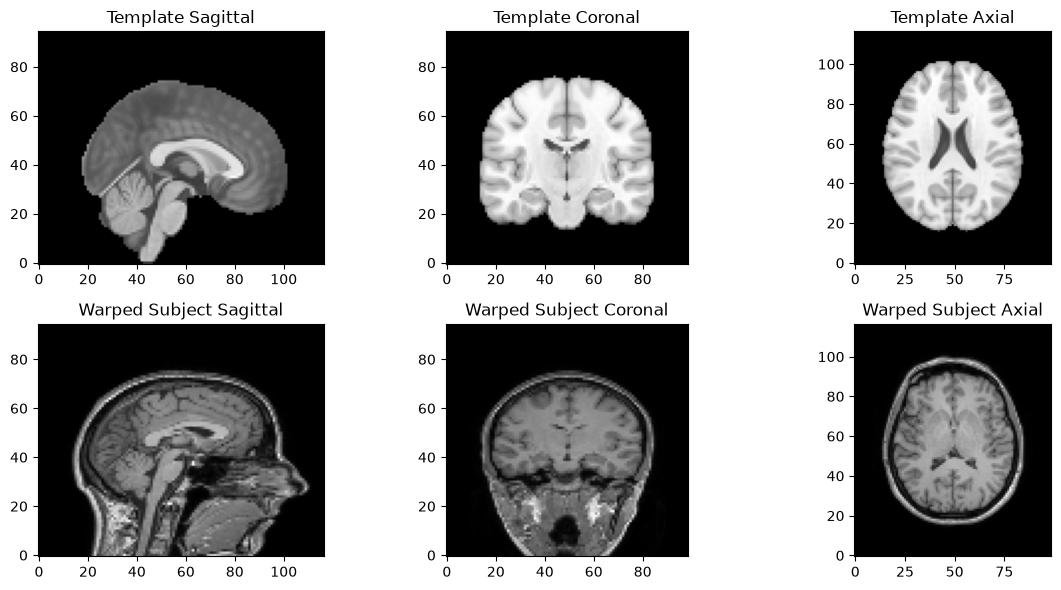

In [14]:
# STEP 5 - Eyeball the alignment (do not skip)
# Plot the middle slices of the warped subject next to the same
# slices of the template, side by side. If registration worked,
# the outlines and major structures sit in the same places in
# both. If it failed, they won't - and every number after this
# would be garbage. This visual check is a professional habit,
# not decoration.

warped = reg['warpedmovout'].numpy()  # Convert ANTs image to numpy array (once)
template_data = template.get_fdata()

# Middle slice indices (warped subject lives on the template's grid)
mid_sagittal = template.shape[0] // 2
mid_coronal = template.shape[1] // 2
mid_axial = template.shape[2] // 2

plt.figure(figsize=(12, 6))
# Template slices
plt.subplot(2, 3, 1)
plt.imshow(template_data[mid_sagittal, :, :].T, cmap='gray', origin='lower')
plt.title('Template Sagittal')
plt.subplot(2, 3, 2)
plt.imshow(template_data[:, mid_coronal, :].T, cmap='gray', origin='lower')
plt.title('Template Coronal')
plt.subplot(2, 3, 3)
plt.imshow(template_data[:, :, mid_axial].T, cmap='gray', origin='lower')
plt.title('Template Axial')
# Warped subject slices
plt.subplot(2, 3, 4)
plt.imshow(warped[mid_sagittal, :, :].T, cmap='gray', origin='lower')
plt.title('Warped Subject Sagittal')
plt.subplot(2, 3, 5)
plt.imshow(warped[:, mid_coronal, :].T, cmap='gray', origin='lower')
plt.title('Warped Subject Coronal')
plt.subplot(2, 3, 6)
plt.imshow(warped[:, :, mid_axial].T, cmap='gray', origin='lower')
plt.title('Warped Subject Axial')
plt.tight_layout()
plt.show()


In [16]:
# STEP 6 - Carry the atlas into the subject
# Use ants.apply_transforms: fixed = the subject (original),
# moving = the atlas maps image, and the transform list that goes
# template -> subject. Which of the two lists from Step 4 is that?
# CRITICAL choice: the 'interpolator' argument. The atlas holds
# category numbers, not brightness - smearing them (smooth
# interpolation) would invent nonsense IDs like 12.6. Find the
# label-safe interpolator option ANTsPy offers for this.
# Save the result. Sanity check: its unique values should be the
# same region IDs as the original atlas - no new numbers.

nib.save(atlas.maps, "data/harvard_oxford_atlas.nii.gz")
atlas_ants = ants.image_read("data/harvard_oxford_atlas.nii.gz")
warped_atlas = ants.apply_transforms(fixed=subject_ants, moving=atlas_ants, transformlist=reg['invtransforms'], interpolator='genericLabel')
np.unique(warped_atlas.numpy())

array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.,
       13., 14., 15., 16., 17., 18., 19., 20., 21., 22., 23., 24., 25.,
       26., 27., 28., 29., 30., 31., 32., 33., 34., 35., 36., 37., 38.,
       39., 40., 41., 42., 43., 44., 45., 46., 47., 48.], dtype=float32)

In [19]:
# STEP 7 - Count the volumes
# For each region ID: count its voxels in the warped atlas array,
# and convert count -> millilitres. You need the volume of one
# voxel of the SUBJECT image: think zooms (notebook 01) and units
# (1 mL = 1000 mm^3).
# Build a table: region name (from the labels list in Step 3)
# alongside its volume in mL, sorted largest first. Print the
# top 10. These are IXI002's first real measurements.

voxel_volume_mm3 = np.prod(subject_ants.spacing)  # Voxel volume in mm^3
warped_arr = warped_atlas.numpy()  # Convert ONCE, reuse below

region_volumes = []
for region_id in range(1, len(labels)):  # Skip background (0)
    voxel_count = np.sum(warped_arr == region_id)
    volume_ml = (voxel_count * voxel_volume_mm3) / 1000  # Convert to mL
    region_volumes.append((labels[region_id], volume_ml))

# Sort by volume in descending order
region_volumes.sort(key=lambda x: x[1], reverse=True)

# Print the top 10
for region_name, volume in region_volumes[:10]:
    print(f"{region_name}: {volume:.2f} mL")


Frontal Pole: 73.27 mL
Lateral Occipital Cortex, superior division: 46.40 mL
Precentral Gyrus: 40.69 mL
Postcentral Gyrus: 32.79 mL
Precuneous Cortex: 26.73 mL
Middle Frontal Gyrus: 25.21 mL
Superior Frontal Gyrus: 24.16 mL
Occipital Pole: 23.70 mL
Temporal Pole: 22.30 mL
Lateral Occipital Cortex, inferior division: 19.36 mL


In [21]:
# STEP 8 - Sanity checks
# Numbers you can't sanity-check aren't results yet. Try:
#   - Sum of all region volumes: cortical grey matter for a whole
#     brain should land in the several-hundred mL range.
#   - Pick a left/right pair of the same region and compare them.
#     Roughly symmetric (within ~10-15%) is expected; a wild
#     mismatch means something upstream went wrong.
# Write what you find - don't just run it, read it.

region_volumes_dict = dict(region_volumes)
total_volume = sum(region_volumes_dict.values())
print(f"Total cortical grey matter volume: {total_volume:.2f} mL")




Total cortical grey matter volume: 620.09 mL


## Checkpoint notes

### What did registration actually change about IXI002's image?

It shifted, rotated, sclaed, and slightly sheared the image so that it lines up with the coordinate system. Now roughly the same spot can be located through a voxel address. 


### Why would smooth interpolation corrupt a label image?

The labels are categories and averaging them invents new values that don't exist and blur boundaries. 

### what's still missing before we can compare fairly across subjects?

Head size, A person with a bigger head has enlarged regions without necessarily being older or younger. Before comparing we need each subjects total intracranial volume (ICV) so regions can be judged relative to the head they reside in. 